In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit

import os

path ='/home/maxi/Documents/psi_hipa_tsm/code/data/qutag'
measurement = 'TagsHistogram_8.txt'
os.listdir(path)

data_path = os.path.join(path, measurement)

df = pd.read_csv(
    data_path,
    sep=";",
    comment="#",       
    header=None,
    names=["bins", "counts"],
    skipinitialspace=True,
)

4.646244482800378e-11


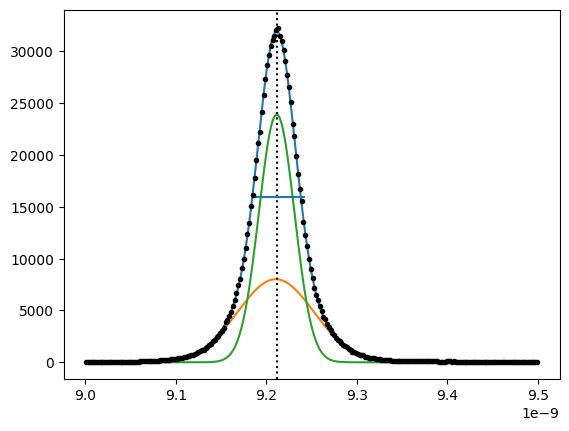

In [7]:
mask = (df.bins > .9e-8) & (df.bins < .95e-8)

gauss = lambda x, A, mu, sig: A*np.exp(-.5*((x-mu)/sig)**2)
double_gauss = lambda x, A, f, mu1, sig1, mu2, sig2: gauss(x, A*f, mu1, sig1) + gauss(x, A*(1-f), mu2, sig2)

p0 = [sum(df.counts[mask]), .95, 9.3e-9, 1e-11, 9.3e-9, 1e-12]

popt, pcov = curve_fit(double_gauss, df.bins[mask], df.counts[mask], p0=p0)


plt.plot(df.bins[mask], double_gauss(df.bins[mask], *popt))
plt.plot(df[mask].bins, gauss(df.bins[mask], popt[0]*(1-popt[1]), popt[-2], popt[-1]))
plt.plot(df[mask].bins, gauss(df.bins[mask], popt[0]*popt[1], popt[2], popt[3]))
plt.axvline(popt[2], color='k', linestyle=':')
plt.errorbar(df.bins[mask], df.counts[mask], yerr=np.sqrt(df.counts[mask]+1), fmt='.', color='k')

print((popt[3]**2+popt[5]**2)**.5)

HM = double_gauss(popt[2], *popt)/2

plt.hlines(HM, x[idx_halfmax_left], x[idx_halfmax_left] - FWHM)

residuals = df.counts[mask] - double_gauss(df.bins[mask], *popt)

In [6]:
x = np.arange(9.1e-9, 9.3e-9, 1e-15)
np.shape(x)

idx_halfmax_left = np.where(np.abs(HM - double_gauss(x[x < popt[2]], *popt)) == np.min(np.abs(HM - double_gauss(x[x < popt[2]], *popt))))
idx_halfmax_right = np.where(np.abs(HM - double_gauss(x[x > popt[2]], *popt)) == np.min(np.abs(HM - double_gauss(x[x > popt[2]], *popt))))

FWHM = x[idx_halfmax_right] - x[idx_halfmax_left]
FWHM/2/(np.sqrt(2*np.log(2)))

array([-2.45865921e-11])

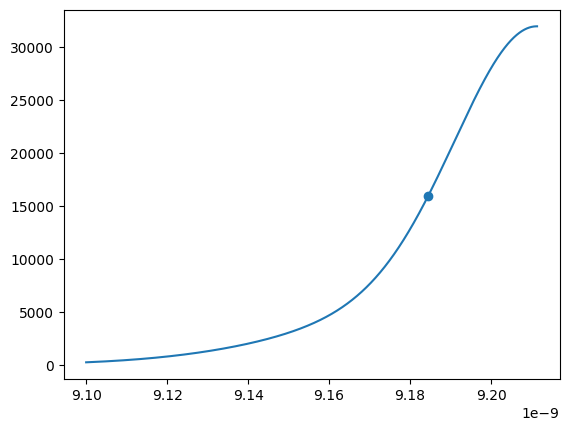

In [16]:

plt.plot(x[x < popt[2]], double_gauss(x[x < popt[2]], *popt))
plt.scatter(x[idx_halfmax_left], HM)